In [1]:
!pip -q install kagglehub opencv-contrib-python-headless pandas matplotlib pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 11.9 MB/s eta 0:00:00


In [2]:
import os
import random
import time
import json
import shutil
import warnings
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageEnhance, ImageFile
from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

# Reproducible experiments
random.seed(42)
np.random.seed(42)

# Download directly from Kaggle
import kagglehub

DATASET_PATH = kagglehub.dataset_download(
    "balabaskar/wonders-of-the-world-image-classification"
)

DATASET_PATH = Path(DATASET_PATH)

print("Dataset downloaded successfully.")
print("Dataset path:", DATASET_PATH)

# Show the top-level folder structure
for item in list(DATASET_PATH.iterdir())[:30]:
    print(("DIR " if item.is_dir() else "FILE"), item.name)

100%|██████████| 432M/432M [00:02<00:00, 162MB/s]

Extracting files...


Dataset downloaded successfully.
Dataset path: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2
DIR  Wonders of World
FILE wonders_of_world_images.csv


In [4]:

# CELL 3 — Robust landmark detection and dataset organization

from pathlib import Path
from PIL import Image, ImageFile
import random
import shutil

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Verify that Cell 2 downloaded the dataset
DATASET_PATH = Path(DATASET_PATH)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset directory does not exist: {DATASET_PATH}\n"
        "Run Cell 2 again to download the Kaggle dataset."
    )

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Accepted folder names for each required landmark
LANDMARK_ALIASES = {
    "Eiffel Tower": [
        "eiffel tower", "eiffel_tower", "eiffeltower"
    ],
    "Taj Mahal": [
        "taj mahal", "taj_mahal", "tajmahal"
    ],
    "Great Wall of China": [
        "great wall of china", "great_wall_of_china",
        "greatwallofchina", "great wall"
    ],
    "Statue of Liberty": [
        "statue of liberty", "statue_of_liberty",
        "statueofliberty"
    ],
    "Colosseum": [
        "colosseum", "roman colosseum",
        "roman_colosseum", "coliseum"
    ]
}

def normalize_name(name):
    return "".join(
        character.lower()
        for character in str(name)
        if character.isalnum()
    )

def get_images(folder):
    """Find images recursively, including nested subfolders."""
    result = []

    try:
        for path in folder.rglob("*"):
            if (
                path.is_file()
                and path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                result.append(path)
    except PermissionError:
        pass

    return sorted(set(result))

# Print useful diagnostic information
print("Dataset root:", DATASET_PATH)
print("\nSearching for landmark image folders...")

all_dirs = [
    path for path in DATASET_PATH.rglob("*")
    if path.is_dir()
]

# Include the root in case the dataset itself is a class folder
all_dirs.insert(0, DATASET_PATH)

landmark_folders = {}

for landmark, aliases in LANDMARK_ALIASES.items():
    alias_keys = {normalize_name(alias) for alias in aliases}
    candidates = []

    for folder in all_dirs:
        folder_key = normalize_name(folder.name)

        # Exact matching first, then conservative partial matching
        exact_match = folder_key in alias_keys

        partial_match = any(
            len(alias) >= 8
            and (folder_key in alias or alias in folder_key)
            for alias in alias_keys
        )

        if exact_match or partial_match:
            images = get_images(folder)

            if images:
                candidates.append((folder, images, exact_match))

    if candidates:
        # Prefer an exact folder-name match; then the most images
        candidates.sort(
            key=lambda item: (
                item[2],
                len(item[1]),
                -len(item[0].parts)
            ),
            reverse=True
        )

        chosen_folder, chosen_images, _ = candidates[0]

        landmark_folders[landmark] = (
            chosen_folder,
            chosen_images
        )

        print(
            f"[FOUND] {landmark}: {len(chosen_images)} images"
        )
        print(f"        Folder: {chosen_folder}")

    else:
        print(f"[NOT FOUND] {landmark}")

print("\nLandmarks discovered:", len(landmark_folders), "/ 5")

# If the names do not match, show available folders to aid diagnosis
if len(landmark_folders) < 5:
    print("\nAvailable folders in the downloaded dataset:")

    for folder in all_dirs[:100]:
        images = get_images(folder)

        if images:
            print(f"{folder.name}: {len(images)} images")

    raise RuntimeError(
        "\nNot all five landmark categories were found. "
        "Check the printed folder names above. The Kaggle dataset "
        "may use different class names or may not contain all five "
        "required landmarks. Update LANDMARK_ALIASES to match the "
        "actual dataset before continuing."
    )

# Prepare a clean working directory
WORK_DIR = Path("/content/landmark_sift_lab")
REFERENCE_DIR = WORK_DIR / "reference_images"
QUERY_DIR = WORK_DIR / "query_images"

if WORK_DIR.exists():
    shutil.rmtree(WORK_DIR)

REFERENCE_DIR.mkdir(parents=True, exist_ok=True)
QUERY_DIR.mkdir(parents=True, exist_ok=True)

# Keep the dataset manageable for Google Colab
MAX_IMAGES_PER_LANDMARK = 100
MIN_IMAGES_PER_LANDMARK = 5

landmark_files = {}

for landmark, (source_folder, image_paths) in landmark_folders.items():
    valid_images = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image.verify()
            valid_images.append(image_path)
        except Exception:
            print("Skipping invalid image:", image_path)

    # Remove duplicate paths and randomize selection
    valid_images = list(dict.fromkeys(valid_images))
    random.Random(42).shuffle(valid_images)
    valid_images = valid_images[:MAX_IMAGES_PER_LANDMARK]

    if len(valid_images) < MIN_IMAGES_PER_LANDMARK:
        raise RuntimeError(
            f"{landmark} has only {len(valid_images)} valid images. "
            f"At least {MIN_IMAGES_PER_LANDMARK} are required."
        )

    landmark_files[landmark] = valid_images

print("\nCELL 3 COMPLETED SUCCESSFULLY")
print("=" * 45)

for landmark, paths in landmark_files.items():
    print(f"{landmark}: {len(paths)} valid images")

print("\nReady to run Cell 4.")


Dataset root: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2

Searching for landmark image folders...
[FOUND] Eiffel Tower: 391 images
        Folder: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/eiffel_tower
[FOUND] Taj Mahal: 158 images
        Folder: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/taj_mahal
[FOUND] Great Wall of China: 392 images
        Folder: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/great_wall_of_china
[FOUND] Statue of Liberty: 238 images
        Folder: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/statue_of_liberty
[FOUND] Colosseum: 394 images
        Folder: /root/.cache/kagg

Reference images: 375
Test images: 125

Reference distribution:


,images
landmark,
Colosseum,75
Eiffel Tower,75
Great Wall of China,75
Statue of Liberty,75
Taj Mahal,75



Test distribution:


,images
landmark,
Colosseum,25
Eiffel Tower,25
Great Wall of China,25
Statue of Liberty,25
Taj Mahal,25


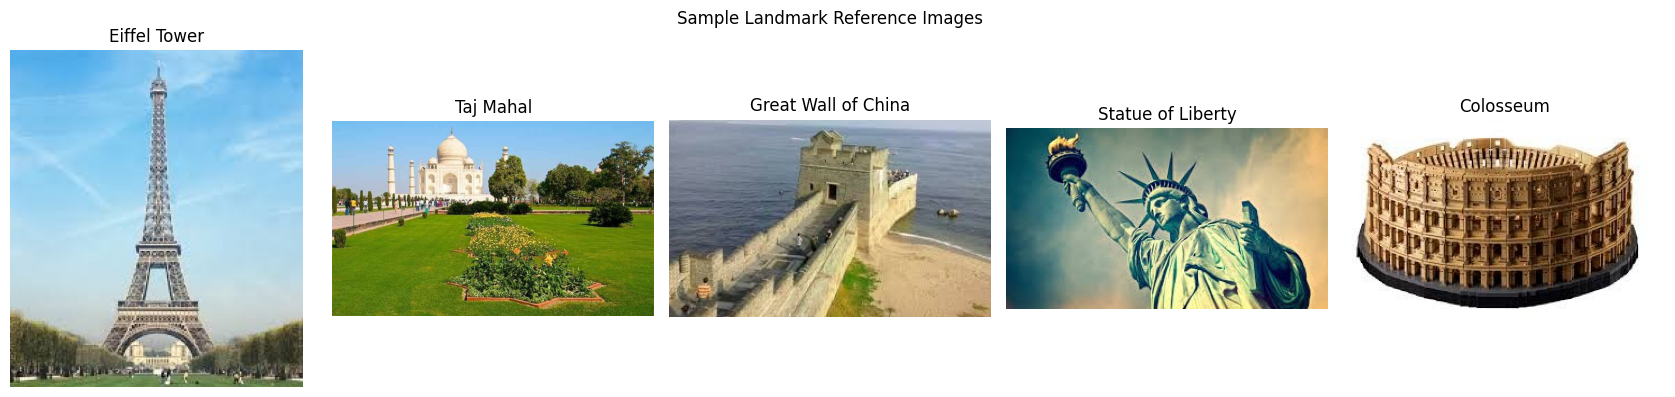

In [5]:
from sklearn.model_selection import train_test_split

reference_records = []
test_records = []

for landmark, files in landmark_files.items():
    # Use separate images for reference and testing
    train_files, test_files = train_test_split(
        files,
        test_size=0.25,
        random_state=42
    )

    ref_class_dir = REFERENCE_DIR / landmark
    test_class_dir = QUERY_DIR / landmark

    ref_class_dir.mkdir(parents=True, exist_ok=True)
    test_class_dir.mkdir(parents=True, exist_ok=True)

    for i, src in enumerate(train_files):
        dst = ref_class_dir / f"{i:04d}{src.suffix.lower()}"
        shutil.copy2(src, dst)
        reference_records.append({
            "landmark": landmark,
            "path": str(dst)
        })

    for i, src in enumerate(test_files):
        dst = test_class_dir / f"{i:04d}{src.suffix.lower()}"
        shutil.copy2(src, dst)
        test_records.append({
            "landmark": landmark,
            "path": str(dst)
        })

reference_df = pd.DataFrame(reference_records)
test_df = pd.DataFrame(test_records)

print("Reference images:", len(reference_df))
print("Test images:", len(test_df))
print("\nReference distribution:")
display(reference_df.groupby("landmark").size().rename("images").to_frame())

print("\nTest distribution:")
display(test_df.groupby("landmark").size().rename("images").to_frame())

# Display sample images
fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, landmark in zip(axes, landmark_files.keys()):
    path = reference_df.loc[
        reference_df["landmark"] == landmark, "path"
    ].iloc[0]

    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(landmark)
    ax.axis("off")

plt.suptitle("Sample Landmark Reference Images")
plt.tight_layout()
plt.show()

In [6]:
# SIFT is available in OpenCV contrib builds.
if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError(
        "SIFT is unavailable. Reinstall opencv-contrib-python-headless "
        "and restart the Colab runtime."
    )

sift = cv2.SIFT_create(
    nfeatures=2500,
    contrastThreshold=0.04,
    edgeThreshold=10,
    sigma=1.6
)

# SIFT descriptors are floating-point vectors, so use L2 distance.
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Ratio-test threshold. This is an experimental parameter, not a guarantee.
LOWE_RATIO = 0.75

reference_database = []

def load_gray_image(path):
    image = cv2.imread(str(path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return image, gray

for _, row in reference_df.iterrows():
    loaded = load_gray_image(row["path"])

    if loaded is None:
        continue

    image, gray = loaded
    keypoints, descriptors = sift.detectAndCompute(gray, None)

    if descriptors is None or len(keypoints) < 4:
        continue

    reference_database.append({
        "landmark": row["landmark"],
        "path": row["path"],
        "image": image,
        "gray": gray,
        "keypoints": keypoints,
        "descriptors": descriptors
    })

if not reference_database:
    raise RuntimeError("No usable SIFT reference descriptors were extracted.")

print("Reference images with usable descriptors:", len(reference_database))
print("Total reference descriptors:",
      sum(len(item["descriptors"]) for item in reference_database))

Reference images with usable descriptors: 374
Total reference descriptors: 415401


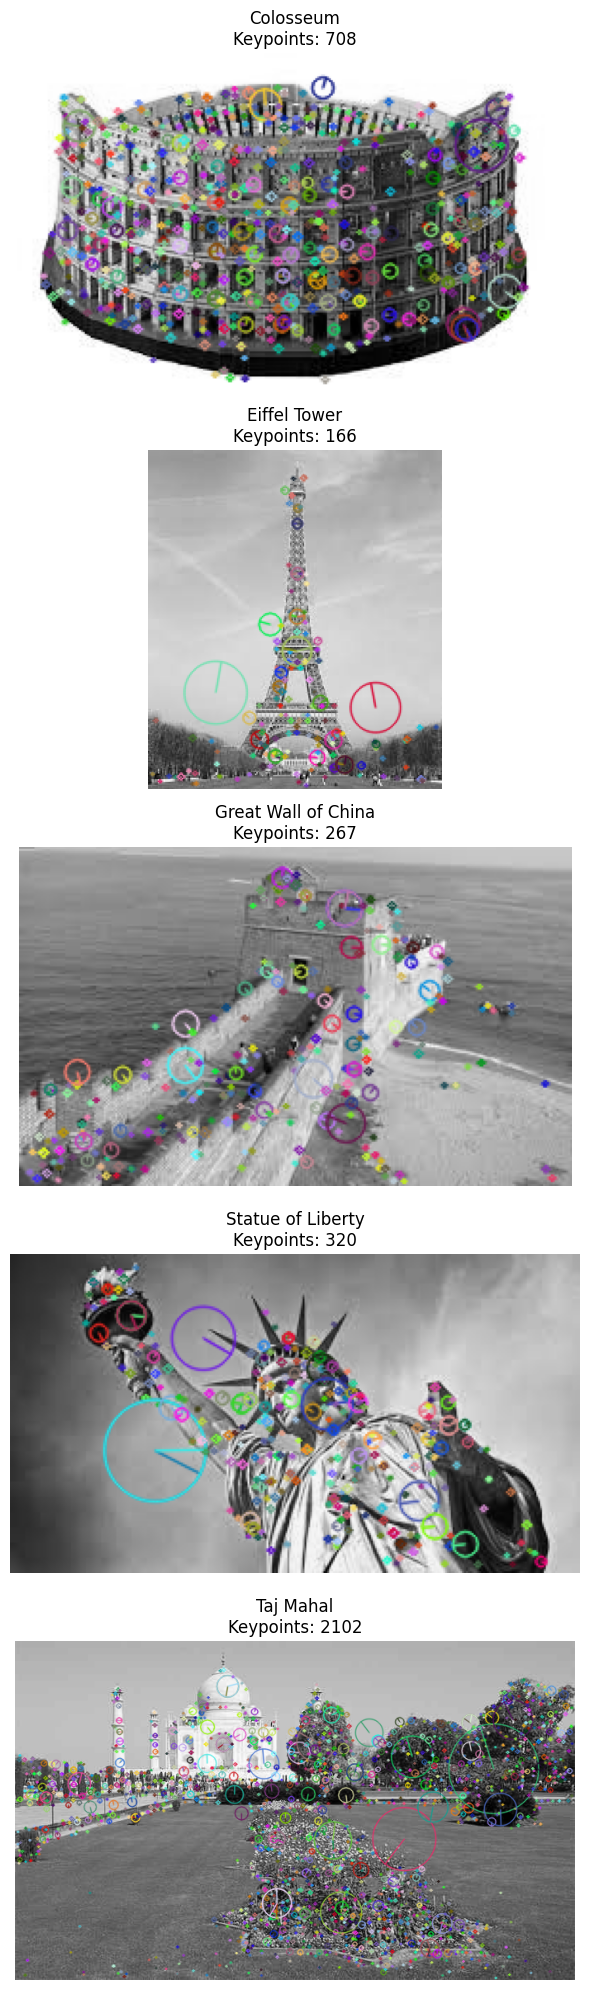

In [7]:
def display_sift_keypoints(database, images_per_class=1):
    classes = sorted(set(item["landmark"] for item in database))

    fig, axes = plt.subplots(
        len(classes), images_per_class,
        figsize=(6 * images_per_class, 4 * len(classes)),
        squeeze=False
    )

    for r, landmark in enumerate(classes):
        examples = [
            item for item in database
            if item["landmark"] == landmark
        ][:images_per_class]

        for c in range(images_per_class):
            ax = axes[r, c]

            if c >= len(examples):
                ax.axis("off")
                continue

            item = examples[c]

            drawn = cv2.drawKeypoints(
                item["gray"],
                item["keypoints"],
                None,
                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
            )

            ax.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
            ax.set_title(
                f'{landmark}\nKeypoints: {len(item["keypoints"])}'
            )
            ax.axis("off")

    plt.tight_layout()
    plt.show()

display_sift_keypoints(reference_database)

In [8]:
def reliable_matches(query_descriptors, reference_descriptors):
    if (
        query_descriptors is None
        or reference_descriptors is None
        or len(query_descriptors) < 2
        or len(reference_descriptors) < 2
    ):
        return []

    try:
        knn_matches = bf.knnMatch(
            query_descriptors,
            reference_descriptors,
            k=2
        )
    except cv2.error:
        return []

    good = []

    for pair in knn_matches:
        if len(pair) != 2:
            continue

        first, second = pair

        if first.distance < LOWE_RATIO * second.distance:
            good.append(first)

    return good


def compare_query_to_reference(query_descriptors, reference_item):
    matches = reliable_matches(
        query_descriptors,
        reference_item["descriptors"]
    )

    return matches


print("KNN matching and Lowe's ratio test are ready.")
print("Distance metric: Euclidean (L2)")
print("K:", 2)
print("Lowe ratio threshold:", LOWE_RATIO)

KNN matching and Lowe's ratio test are ready.
Distance metric: Euclidean (L2)
K: 2
Lowe ratio threshold: 0.75


In [9]:
# Tune these thresholds using the evaluation results.
MIN_GOOD_MATCHES = 12
MIN_RANSAC_INLIERS = 8
MIN_INLIER_RATIO = 0.35
MIN_INLIERS_FOR_LOCALIZATION = 8

def recognize_landmark(query_path, show_results=True):
    start_time = time.perf_counter()

    loaded = load_gray_image(query_path)

    if loaded is None:
        raise ValueError(f"Could not load query image: {query_path}")

    query_bgr, query_gray = loaded
    query_kp, query_desc = sift.detectAndCompute(query_gray, None)

    if query_desc is None or len(query_kp) < 4:
        elapsed = time.perf_counter() - start_time

        result = {
            "query_path": str(query_path),
            "predicted_landmark": "Unknown",
            "reliable_matches": 0,
            "ransac_inliers": 0,
            "inlier_ratio": 0.0,
            "recognized": False,
            "query_keypoints": len(query_kp),
            "processing_time_sec": elapsed,
            "best_reference": None,
            "good_matches": [],
            "inlier_matches": [],
            "homography": None,
            "projected_corners": None,
            "query_image": query_bgr,
            "query_gray": query_gray,
            "query_keypoint_objects": query_kp
        }

        if show_results:
            print("Rejected: insufficient SIFT features.")
            plt.figure(figsize=(7, 5))
            plt.imshow(cv2.cvtColor(query_bgr, cv2.COLOR_BGR2RGB))
            plt.title("Unknown — insufficient features")
            plt.axis("off")
            plt.show()

        return result

    # Keep the best reference image for each landmark.
    best_per_landmark = {}

    for item in reference_database:
        good = compare_query_to_reference(query_desc, item)

        # Rank using match count, with average descriptor distance as a tie-breaker.
        mean_distance = (
            float(np.mean([m.distance for m in good])
                  ) if good else float("inf")
        )

        rank_score = len(good)

        candidate = {
            "item": item,
            "matches": good,
            "mean_distance": mean_distance,
            "rank_score": rank_score
        }

        label = item["landmark"]

        if label not in best_per_landmark:
            best_per_landmark[label] = candidate
        else:
            old = best_per_landmark[label]

            if (
                candidate["rank_score"] > old["rank_score"]
                or (
                    candidate["rank_score"] == old["rank_score"]
                    and candidate["mean_distance"] < old["mean_distance"]
                )
            ):
                best_per_landmark[label] = candidate

    ranking = sorted(
        best_per_landmark.items(),
        key=lambda pair: (
            pair[1]["rank_score"],
            -pair[1]["mean_distance"]
        ),
        reverse=True
    )

    if not ranking:
        elapsed = time.perf_counter() - start_time

        return {
            "query_path": str(query_path),
            "predicted_landmark": "Unknown",
            "reliable_matches": 0,
            "ransac_inliers": 0,
            "inlier_ratio": 0.0,
            "recognized": False,
            "query_keypoints": len(query_kp),
            "processing_time_sec": elapsed,
            "best_reference": None,
            "good_matches": [],
            "inlier_matches": [],
            "homography": None,
            "projected_corners": None,
            "query_image": query_bgr,
            "query_gray": query_gray,
            "query_keypoint_objects": query_kp
        }

    predicted_label, best = ranking[0]
    best_item = best["item"]
    good_matches = best["matches"]

    # Geometric verification: reference coordinates -> query coordinates.
    homography = None
    inlier_matches = []
    projected_corners = None
    inlier_ratio = 0.0

    if len(good_matches) >= 4:
        src_pts = np.float32([
            best_item["keypoints"][m.trainIdx].pt
            for m in good_matches
        ]).reshape(-1, 1, 2)

        dst_pts = np.float32([
            query_kp[m.queryIdx].pt
            for m in good_matches
        ]).reshape(-1, 1, 2)

        homography, mask = cv2.findHomography(
            src_pts,
            dst_pts,
            cv2.RANSAC,
            5.0,
            maxIters=3000,
            confidence=0.995
        )

        if homography is not None and mask is not None:
            inlier_mask = mask.ravel().astype(bool)
            inlier_matches = [
                m for m, keep in zip(good_matches, inlier_mask)
                if keep
            ]

            inlier_ratio = len(inlier_matches) / max(len(good_matches), 1)

            h, w = best_item["gray"].shape

            corners = np.float32([
                [0, 0],
                [w - 1, 0],
                [w - 1, h - 1],
                [0, h - 1]
            ]).reshape(-1, 1, 2)

            candidate_corners = cv2.perspectiveTransform(
                corners, homography
            ).reshape(-1, 2)

            qh, qw = query_gray.shape

            # Reject degenerate or implausible quadrilaterals.
            polygon_area = abs(
                cv2.contourArea(candidate_corners.astype(np.float32))
            )

            valid_corners = (
                np.isfinite(candidate_corners).all()
                and np.max(np.abs(candidate_corners)) < 10 * max(qw, qh)
            )

            if (
                valid_corners
                and polygon_area >= 100
                and polygon_area <= 4 * qw * qh
                and cv2.isContourConvex(candidate_corners.astype(np.float32))
            ):
                projected_corners = candidate_corners

    good_count = len(good_matches)
    inlier_count = len(inlier_matches)

    # Require both descriptor evidence and geometric consistency.
    recognized = (
        good_count >= MIN_GOOD_MATCHES
        and inlier_count >= MIN_RANSAC_INLIERS
        and inlier_ratio >= MIN_INLIER_RATIO
    )

    elapsed = time.perf_counter() - start_time

    result = {
        "query_path": str(query_path),
        "predicted_landmark": predicted_label if recognized else "Unknown",
        "candidate_landmark": predicted_label,
        "reliable_matches": good_count,
        "ransac_inliers": inlier_count,
        "inlier_ratio": inlier_ratio,
        "recognized": recognized,
        "query_keypoints": len(query_kp),
        "processing_time_sec": elapsed,
        "best_reference": best_item,
        "good_matches": good_matches,
        "inlier_matches": inlier_matches,
        "homography": homography,
        "projected_corners": projected_corners,
        "query_image": query_bgr,
        "query_gray": query_gray,
        "query_keypoint_objects": query_kp,
        "ranking": [
            {
                "landmark": label,
                "reliable_matches": entry["rank_score"],
                "mean_distance": entry["mean_distance"]
            }
            for label, entry in ranking
        ]
    }

    if show_results:
        status = "RECOGNIZED" if recognized else "REJECTED / UNKNOWN"

        print("Decision:", status)
        print("Predicted landmark:", result["predicted_landmark"])
        print("Best candidate:", result["candidate_landmark"])
        print("Query keypoints:", result["query_keypoints"])
        print("Reliable matches:", good_count)
        print("RANSAC inliers:", inlier_count)
        print(f"Inlier ratio: {inlier_ratio:.3f}")
        print(f"Processing time: {elapsed:.4f} seconds")

        # Show the query image and detected SIFT keypoints.
        query_keypoint_img = cv2.drawKeypoints(
            query_gray,
            query_kp,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].imshow(cv2.cvtColor(query_bgr, cv2.COLOR_BGR2RGB))
        axes[0].set_title("Query image")
        axes[0].axis("off")

        axes[1].imshow(
            cv2.cvtColor(query_keypoint_img, cv2.COLOR_BGR2RGB)
        )
        axes[1].set_title(f"SIFT keypoints: {len(query_kp)}")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

        # Show reliable descriptor matches.
        match_vis = cv2.drawMatches(
            best_item["image"],
            best_item["keypoints"],
            query_bgr,
            query_kp,
            good_matches[:60],
            None,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

        plt.figure(figsize=(16, 7))
        plt.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
        plt.title(f"Reliable SIFT matches — {predicted_label}")
        plt.axis("off")
        plt.show()

        # Draw a localization polygon only when geometry is reliable.
        localized = query_bgr.copy()

        if (
            recognized
            and projected_corners is not None
            and inlier_count >= MIN_INLIERS_FOR_LOCALIZATION
        ):
            polygon = np.round(projected_corners).astype(np.int32)
            cv2.polylines(
                localized,
                [polygon.reshape(-1, 1, 2)],
                isClosed=True,
                color=(0, 255, 0),
                thickness=4
            )

            title = "Landmark localized by homography + RANSAC"
        else:
            title = "Localization unavailable — unreliable geometry"

        plt.figure(figsize=(9, 6))
        plt.imshow(cv2.cvtColor(localized, cv2.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
        plt.show()

        print("\nCandidate ranking:")
        display(pd.DataFrame(result["ranking"]))

    return result

print("Landmark recognition and localization functions are ready.")

Landmark recognition and localization functions are ready.


In [10]:
# Required for the train/test split in Cell 4 if not already available.
# If Cell 4 has already run successfully, you can skip this line.
!pip -q install scikit-learn

In [11]:
def create_transformed_images(image_bgr):
    """Return controlled variations of an image."""
    h, w = image_bgr.shape[:2]

    # Rotation around the image center
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), 25, 1.0)
    rotated = cv2.warpAffine(
        image_bgr,
        matrix,
        (w, h),
        borderMode=cv2.BORDER_REFLECT
    )

    # Resize to a smaller image and back to the original size
    small = cv2.resize(
        image_bgr,
        (max(1, w // 2), max(1, h // 2)),
        interpolation=cv2.INTER_AREA
    )
    resized = cv2.resize(
        small, (w, h), interpolation=cv2.INTER_LINEAR
    )

    # Reduced brightness
    darker = cv2.convertScaleAbs(image_bgr, alpha=0.45, beta=0)

    return {
        "Original": image_bgr,
        "Rotated 25 degrees": rotated,
        "Resized": resized,
        "Reduced brightness": darker
    }


def evaluate_single_image(image_bgr, true_label, condition, temp_path):
    if not cv2.imwrite(str(temp_path), image_bgr):
        raise IOError(f"Could not save temporary query: {temp_path}")

    result = recognize_landmark(temp_path, show_results=False)

    # Use the predicted candidate to evaluate classification correctness.
    candidate = result.get("candidate_landmark", "Unknown")

    return {
        "condition": condition,
        "true_landmark": true_label,
        "predicted_landmark": result["predicted_landmark"],
        "best_candidate": candidate,
        "query_keypoints": result["query_keypoints"],
        "reliable_matches": result["reliable_matches"],
        "ransac_inliers": result["ransac_inliers"],
        "inlier_ratio": round(result["inlier_ratio"], 3),
        "recognized": result["recognized"],
        "correct_candidate": candidate == true_label,
        "processing_time_sec": round(
            result["processing_time_sec"], 4
        )
    }


# Limit the experiment to a few held-out images per class to keep it practical.
MAX_TEST_IMAGES_PER_CLASS = 5
evaluation_rows = []
temp_query_path = WORK_DIR / "temporary_query.jpg"

for landmark in sorted(test_df["landmark"].unique()):
    paths = test_df.loc[
        test_df["landmark"] == landmark, "path"
    ].tolist()

    random.shuffle(paths)
    paths = paths[:MAX_TEST_IMAGES_PER_CLASS]

    for path in paths:
        image_bgr = cv2.imread(path)

        if image_bgr is None:
            continue

        variants = create_transformed_images(image_bgr)

        for condition, variant in variants.items():
            row = evaluate_single_image(
                variant,
                landmark,
                condition,
                temp_query_path
            )
            evaluation_rows.append(row)

        print("Completed:", landmark, "|", Path(path).name)

evaluation_df = pd.DataFrame(evaluation_rows)

print("\nEvaluation results:")
display(evaluation_df)

print("\nPerformance by test condition:")
condition_summary = (
    evaluation_df.groupby("condition")
    .agg(
        samples=("true_landmark", "count"),
        recognition_rate=("recognized", "mean"),
        candidate_accuracy=("correct_candidate", "mean"),
        mean_matches=("reliable_matches", "mean"),
        mean_inliers=("ransac_inliers", "mean"),
        mean_processing_time=("processing_time_sec", "mean")
    )
    .reset_index()
)

condition_summary["recognition_rate"] *= 100
condition_summary["candidate_accuracy"] *= 100

display(condition_summary.round(2))

Completed: Colosseum | 0016.jpg
Completed: Colosseum | 0012.jpg
Completed: Colosseum | 0009.jpg
Completed: Colosseum | 0019.jpg
Completed: Colosseum | 0018.jpg
Completed: Eiffel Tower | 0002.jpg
Completed: Eiffel Tower | 0012.jpg
Completed: Eiffel Tower | 0011.jpg
Completed: Eiffel Tower | 0007.jpg
Completed: Eiffel Tower | 0024.jpg
Completed: Great Wall of China | 0022.jpg
Completed: Great Wall of China | 0000.jpg
Completed: Great Wall of China | 0008.jpg
Completed: Great Wall of China | 0023.jpg
Completed: Great Wall of China | 0010.jpg
Completed: Statue of Liberty | 0012.jpg
Completed: Statue of Liberty | 0011.jpg
Completed: Statue of Liberty | 0013.jpg
Completed: Statue of Liberty | 0009.jpg
Completed: Statue of Liberty | 0019.jpg
Completed: Taj Mahal | 0009.jpg
Completed: Taj Mahal | 0007.jpg
Completed: Taj Mahal | 0000.jpg
Completed: Taj Mahal | 0013.jpg
Completed: Taj Mahal | 0005.jpg

Evaluation results:


,condition,true_landmark,predicted_landmark,best_candidate,query_keypoints,reliable_matches,ransac_inliers,inlier_ratio,recognized,correct_candidate,processing_time_sec
0,Original,Colosseum,Colosseum,Colosseum,521,183,147,0.803,True,True,7.9000
1,Rotated 25 degrees,Colosseum,Colosseum,Colosseum,435,170,138,0.812,True,True,6.4646
2,Resized,Colosseum,Colosseum,Colosseum,611,167,144,0.862,True,True,8.8549
3,Reduced brightness,Colosseum,Colosseum,Colosseum,510,179,146,0.816,True,True,5.7494
4,Original,Colosseum,Unknown,Statue of Liberty,2501,146,4,0.027,False,False,27.7175
...,...,...,...,...,...,...,...,...,...,...,...
95,Reduced brightness,Taj Mahal,Unknown,Statue of Liberty,2500,175,7,0.040,False,False,29.4346
96,Original,Taj Mahal,Taj Mahal,Taj Mahal,2500,204,102,0.500,True,True,27.3511
97,Rotated 25 degrees,Taj Mahal,Taj Mahal,Taj Mahal,2500,220,125,0.568,True,True,27.3599
98,Resized,Taj Mahal,Taj Mahal,Taj Mahal,2500,145,75,0.517,True,True,27.2473



Performance by test condition:


,condition,samples,recognition_rate,candidate_accuracy,mean_matches,mean_inliers,mean_processing_time
0,Original,25,52.0,56.0,115.40,61.92,13.59
1,Reduced brightness,25,48.0,68.0,92.28,47.32,9.74
2,Resized,25,52.0,60.0,105.60,71.08,12.47
3,Rotated 25 degrees,25,48.0,68.0,119.52,62.20,14.30


In [12]:
viewpoint_rows = []

for landmark in sorted(test_df["landmark"].unique()):
    paths = test_df.loc[
        test_df["landmark"] == landmark, "path"
    ].tolist()

    if not paths:
        continue

    path = paths[-1]
    image_bgr = cv2.imread(path)

    if image_bgr is None:
        continue

    row = evaluate_single_image(
        image_bgr,
        landmark,
        "Different source image / viewpoint proxy",
        temp_query_path
    )

    viewpoint_rows.append(row)

viewpoint_df = pd.DataFrame(viewpoint_rows)

print("Different-source-image evaluation:")
display(viewpoint_df)

if len(viewpoint_df):
    print(
        "Candidate accuracy:",
        f'{100 * viewpoint_df["correct_candidate"].mean():.2f}%'
    )

Different-source-image evaluation:


,condition,true_landmark,predicted_landmark,best_candidate,query_keypoints,reliable_matches,ransac_inliers,inlier_ratio,recognized,correct_candidate,processing_time_sec
0,Different source image / viewpoint proxy,Colosseum,Colosseum,Colosseum,453,38,26,0.684,True,True,6.8015
1,Different source image / viewpoint proxy,Eiffel Tower,Unknown,Statue of Liberty,1505,312,7,0.022,False,False,17.1319
2,Different source image / viewpoint proxy,Great Wall of China,Unknown,Statue of Liberty,480,12,0,0.000,False,False,5.2719
3,Different source image / viewpoint proxy,Statue of Liberty,Unknown,Taj Mahal,245,14,6,0.429,False,False,2.8050
4,Different source image / viewpoint proxy,Taj Mahal,Taj Mahal,Taj Mahal,269,17,12,0.706,True,True,2.9584


Candidate accuracy: 40.00%


Upload a landmark image to test the SIFT recognition system.


Saving Screenshot 2026-10-15 094938.png to Screenshot 2026-10-15 094938.png
Decision: REJECTED / UNKNOWN
Predicted landmark: Unknown
Best candidate: Taj Mahal
Query keypoints: 1163
Reliable matches: 165
RANSAC inliers: 8
Inlier ratio: 0.048
Processing time: 12.9029 seconds


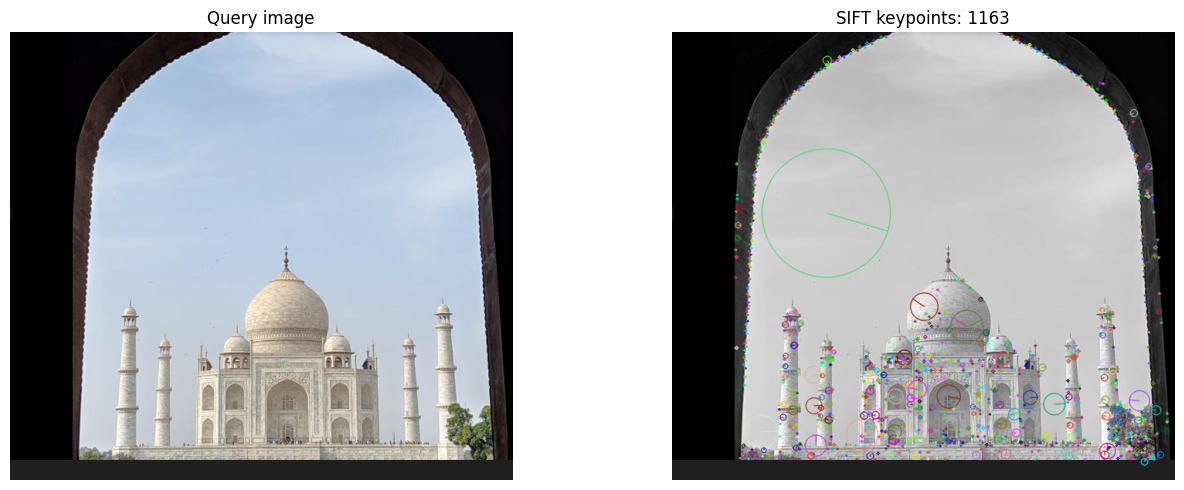

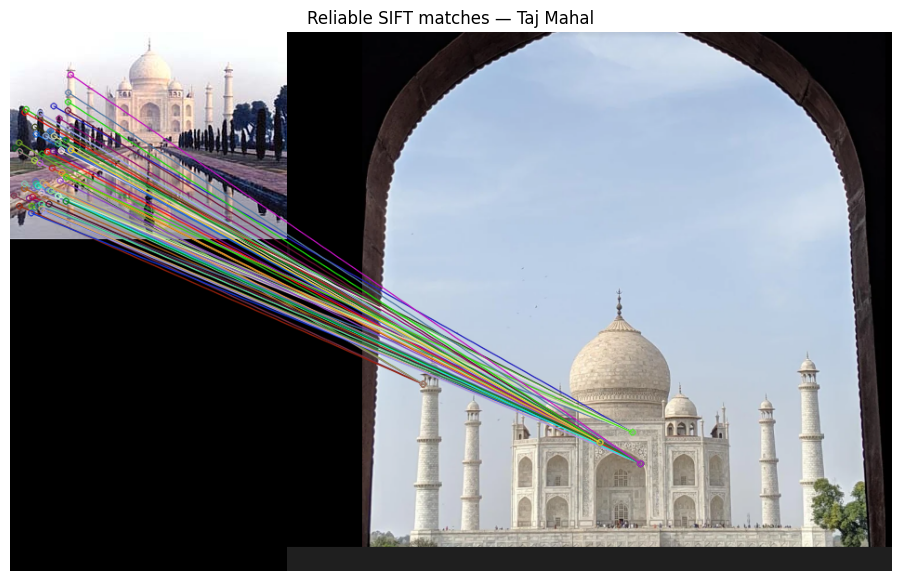

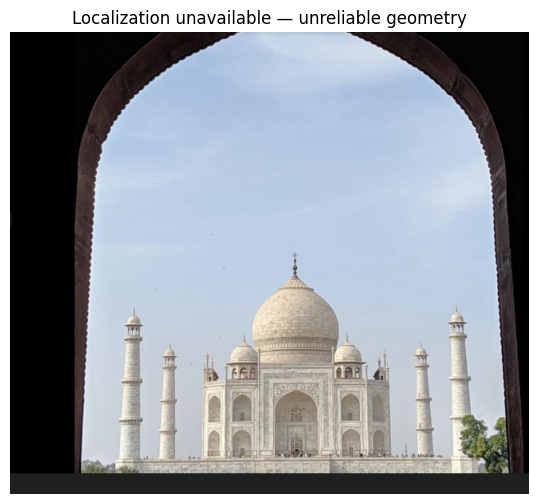


Candidate ranking:


,landmark,reliable_matches,mean_distance
0,Taj Mahal,165,157.924049
1,Statue of Liberty,154,157.639298
2,Colosseum,114,180.751924
3,Great Wall of China,113,149.007144
4,Eiffel Tower,99,181.244136



FINAL RECOGNITION RESULT
Landmark: Unknown
Decision: Rejected
Keypoints: 1163
Reliable matches: 165
RANSAC inliers: 8
Time: 12.902886690000287 seconds


In [15]:
from google.colab import files

print("Upload a landmark image to test the SIFT recognition system.")
uploaded_query = files.upload()

if uploaded_query:
    query_filename = next(iter(uploaded_query))
    query_path = Path("/content") / query_filename

    query_result = recognize_landmark(
        query_path,
        show_results=True
    )

    print("\nFINAL RECOGNITION RESULT")
    print("=" * 40)
    print("Landmark:", query_result["predicted_landmark"])
    print("Decision:", "Recognized" if query_result["recognized"] else "Rejected")
    print("Keypoints:", query_result["query_keypoints"])
    print("Reliable matches:", query_result["reliable_matches"])
    print("RANSAC inliers:", query_result["ransac_inliers"])
    print("Time:", query_result["processing_time_sec"], "seconds")

In [16]:
RESULTS_DIR = WORK_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

evaluation_csv = RESULTS_DIR / "sift_evaluation_results.csv"
summary_csv = RESULTS_DIR / "sift_condition_summary.csv"

evaluation_df.to_csv(evaluation_csv, index=False)
condition_summary.to_csv(summary_csv, index=False)

print("Saved files:")
print(evaluation_csv)
print(summary_csv)

display(evaluation_df.head(10))
display(condition_summary.round(2))

# Download the files to your computer
files.download(str(evaluation_csv))
files.download(str(summary_csv))

Saved files:
/content/landmark_sift_lab/results/sift_evaluation_results.csv
/content/landmark_sift_lab/results/sift_condition_summary.csv


,condition,true_landmark,predicted_landmark,best_candidate,query_keypoints,reliable_matches,ransac_inliers,inlier_ratio,recognized,correct_candidate,processing_time_sec
0,Original,Colosseum,Colosseum,Colosseum,521,183,147,0.803,True,True,7.9000
1,Rotated 25 degrees,Colosseum,Colosseum,Colosseum,435,170,138,0.812,True,True,6.4646
2,Resized,Colosseum,Colosseum,Colosseum,611,167,144,0.862,True,True,8.8549
3,Reduced brightness,Colosseum,Colosseum,Colosseum,510,179,146,0.816,True,True,5.7494
4,Original,Colosseum,Unknown,Statue of Liberty,2501,146,4,0.027,False,False,27.7175
5,Rotated 25 degrees,Colosseum,Unknown,Statue of Liberty,2500,124,5,0.040,False,False,27.4070
6,Resized,Colosseum,Unknown,Statue of Liberty,2500,104,5,0.048,False,False,28.3224
7,Reduced brightness,Colosseum,Unknown,Statue of Liberty,2266,145,6,0.041,False,False,25.0195
8,Original,Colosseum,Colosseum,Colosseum,442,94,89,0.947,True,True,4.8867
9,Rotated 25 degrees,Colosseum,Colosseum,Colosseum,590,110,106,0.964,True,True,7.2451


,condition,samples,recognition_rate,candidate_accuracy,mean_matches,mean_inliers,mean_processing_time
0,Original,25,52.0,56.0,115.40,61.92,13.59
1,Reduced brightness,25,48.0,68.0,92.28,47.32,9.74
2,Resized,25,52.0,60.0,105.60,71.08,12.47
3,Rotated 25 degrees,25,48.0,68.0,119.52,62.20,14.30


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown
from google.colab import files

# Output file
REPORT_PATH = Path(
    "/content/landmark_sift_lab/Landmark_Recognition_SIFT_Report.md"
)
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

report = []

def add(text=""):
    report.append(str(text))

# --------------------------------------------------
# 1. Report heading
# --------------------------------------------------
add("# Computer Vision Lab Assignment")
add("## Landmark Recognition Using the SIFT Algorithm")
add()
add(f"**Report generated:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
add()
add("---")
add()

# --------------------------------------------------
# 2. Objective
# --------------------------------------------------
add("## 1. Objective")
add(
    "Develop a computer vision application that recognizes famous "
    "landmarks using SIFT feature extraction, Brute-Force descriptor "
    "matching, Lowe's ratio test, and RANSAC-based geometric verification."
)
add()

# --------------------------------------------------
# 3. Tools
# --------------------------------------------------
add("## 2. Tools and Technologies")
add("- Python")
add("- Google Colab")
add("- OpenCV")
add("- SIFT (Scale-Invariant Feature Transform)")
add("- Brute-Force Matcher with Euclidean (L2) distance")
add("- K-nearest-neighbor matching (k=2)")
add("- Lowe's ratio test")
add("- Homography estimation using RANSAC")
add("- NumPy, Pandas, Matplotlib")
add("- Kaggle dataset")
add()

# --------------------------------------------------
# 4. Dataset
# --------------------------------------------------
add("## 3. Dataset and Reference Database")
add()

if "landmark_files" in globals():
    for landmark, paths in landmark_files.items():
        add(f"- **{landmark}:** {len(paths)} valid source images")
else:
    add("Dataset category counts were not available when this report was generated.")

add()

if "reference_df" in globals():
    add(f"- Reference images prepared: {len(reference_df)}")
if "test_df" in globals():
    add(f"- Held-out test images prepared: {len(test_df)}")

add()
add("Reference images are organized into folders by landmark category.")
add()

# --------------------------------------------------
# 5. Methodology
# --------------------------------------------------
add("## 4. Methodology")
add()
add("### 4.1 SIFT Feature Extraction")
add(
    "Each image is converted to grayscale. SIFT detects distinctive "
    "keypoints and calculates a descriptor vector for each keypoint."
)
add()
add("### 4.2 Feature Matching")
add(
    "The Brute-Force Matcher compares SIFT descriptors using Euclidean "
    "distance. KNN matching retrieves two nearest neighbors, and Lowe's "
    "ratio test filters ambiguous matches."
)
add()
add("### 4.3 Landmark Recognition")
add(
    "The system ranks reference images by reliable descriptor matches. "
    "A landmark is accepted only when the match count, RANSAC inlier count, "
    "and inlier ratio meet the configured thresholds."
)
add()
add("### 4.4 Landmark Localization")
add(
    "Homography estimation with RANSAC checks geometric consistency "
    "between the reference image and query image. When the transformation "
    "passes the implemented checks, the projected reference-image corners "
    "are drawn as a polygon on the query image."
)
add()

if "LOWE_RATIO" in globals():
    add(f"- Lowe ratio threshold: {LOWE_RATIO}")
if "MIN_GOOD_MATCHES" in globals():
    add(f"- Minimum reliable matches: {MIN_GOOD_MATCHES}")
if "MIN_RANSAC_INLIERS" in globals():
    add(f"- Minimum RANSAC inliers: {MIN_RANSAC_INLIERS}")
if "MIN_INLIER_RATIO" in globals():
    add(f"- Minimum inlier ratio: {MIN_INLIER_RATIO}")

add()

# --------------------------------------------------
# 6. Evaluation results
# --------------------------------------------------
add("## 5. Experimental Results")
add()

if "evaluation_df" in globals() and not evaluation_df.empty:
    add("### 5.1 Individual Test Results")
    add()
    add(evaluation_df.to_markdown(index=False))
    add()
else:
    add(
        "The evaluation table is not available. Run the evaluation cell "
        "before generating the report to include actual experimental results."
    )
    add()

if "condition_summary" in globals() and not condition_summary.empty:
    add("### 5.2 Performance by Test Condition")
    add()
    add(condition_summary.round(2).to_markdown(index=False))
    add()
else:
    add("The condition summary is not available yet.")
    add()

# --------------------------------------------------
# 7. Unknown image test
# --------------------------------------------------
add("## 6. Unknown Landmark Test")
add()

if "unknown_result" in globals() and isinstance(unknown_result, dict):
    add(f"- Predicted label: {unknown_result.get('predicted_landmark', 'N/A')}")
    add(f"- Recognized: {unknown_result.get('recognized', 'N/A')}")
    add(f"- Query keypoints: {unknown_result.get('query_keypoints', 'N/A')}")
    add(f"- Reliable matches: {unknown_result.get('reliable_matches', 'N/A')}")
    add(f"- RANSAC inliers: {unknown_result.get('ransac_inliers', 'N/A')}")
else:
    add(
        "The unknown-image test has not been recorded. Run the unknown-image "
        "test cell and regenerate this report to include its result."
    )

add()

# --------------------------------------------------
# 8. Overall performance
# --------------------------------------------------
add("## 7. Performance Analysis")
add()

if "evaluation_df" in globals() and not evaluation_df.empty:
    total = len(evaluation_df)
    recognized_count = int(evaluation_df["recognized"].sum())
    candidate_correct = int(evaluation_df["correct_candidate"].sum())

    add(f"- Total evaluated test cases: {total}")
    add(
        f"- Recognition rate: {recognized_count / total * 100:.2f}% "
        "(percentage accepted by the recognition thresholds)"
    )
    add(
        f"- Candidate classification accuracy: "
        f"{candidate_correct / total * 100:.2f}% "
        "(best candidate compared with the true label, including rejected cases)"
    )

    if "processing_time_sec" in evaluation_df.columns:
        add(
            f"- Mean processing time: "
            f"{evaluation_df['processing_time_sec'].mean():.4f} seconds"
        )
else:
    add("No experimental measurements were available at report-generation time.")

add()

# --------------------------------------------------
# 9. Discussion and limitations
# --------------------------------------------------
add("## 8. Discussion and Limitations")
add()
add(
    "SIFT can identify distinctive local image features and is designed "
    "to be reasonably robust to scale and rotation changes. Matching may "
    "become less reliable when the query image has a substantially different "
    "viewpoint, low resolution, blur, severe illumination changes, or few "
    "distinctive features."
)
add()
add(
    "A high descriptor match count alone does not guarantee correct "
    "recognition. RANSAC provides a geometric consistency check, but "
    "homography-based localization can still fail when images show "
    "different sides or viewpoints of a three-dimensional landmark."
)
add()
add(
    "Recognition thresholds should be evaluated using held-out landmark "
    "images and unrelated unknown images. Results in this report reflect "
    "only the experiments actually executed."
)
add()

# --------------------------------------------------
# 10. Conclusion
# --------------------------------------------------
add("## 9. Conclusion")
add()
add(
    "This project implements a SIFT-based landmark recognition pipeline "
    "that extracts local features, matches descriptors, filters ambiguous "
    "matches, ranks candidate landmarks, and uses RANSAC homography "
    "estimation for geometric verification and localization. The recorded "
    "experimental results provide a basis for assessing its strengths "
    "and limitations."
)
add()

# --------------------------------------------------
# Save report
# --------------------------------------------------
REPORT_PATH.write_text("\n".join(report), encoding="utf-8")

print("Markdown report saved successfully:")
print(REPORT_PATH)
print("File size:", REPORT_PATH.stat().st_size, "bytes")

# Preview the report
display(Markdown(REPORT_PATH.read_text(encoding="utf-8")))

# Download the .md file
files.download(str(REPORT_PATH))


Markdown report saved successfully:
/content/landmark_sift_lab/Landmark_Recognition_SIFT_Report.md
File size: 27798 bytes


# Computer Vision Lab Assignment
## Landmark Recognition Using the SIFT Algorithm

**Report generated:** 2026-10-15 04:52:21

---

## 1. Objective
Develop a computer vision application that recognizes famous landmarks using SIFT feature extraction, Brute-Force descriptor matching, Lowe's ratio test, and RANSAC-based geometric verification.

## 2. Tools and Technologies
- Python
- Google Colab
- OpenCV
- SIFT (Scale-Invariant Feature Transform)
- Brute-Force Matcher with Euclidean (L2) distance
- K-nearest-neighbor matching (k=2)
- Lowe's ratio test
- Homography estimation using RANSAC
- NumPy, Pandas, Matplotlib
- Kaggle dataset

## 3. Dataset and Reference Database

- **Eiffel Tower:** 100 valid source images
- **Taj Mahal:** 100 valid source images
- **Great Wall of China:** 100 valid source images
- **Statue of Liberty:** 100 valid source images
- **Colosseum:** 100 valid source images

- Reference images prepared: 375
- Held-out test images prepared: 125

Reference images are organized into folders by landmark category.

## 4. Methodology

### 4.1 SIFT Feature Extraction
Each image is converted to grayscale. SIFT detects distinctive keypoints and calculates a descriptor vector for each keypoint.

### 4.2 Feature Matching
The Brute-Force Matcher compares SIFT descriptors using Euclidean distance. KNN matching retrieves two nearest neighbors, and Lowe's ratio test filters ambiguous matches.

### 4.3 Landmark Recognition
The system ranks reference images by reliable descriptor matches. A landmark is accepted only when the match count, RANSAC inlier count, and inlier ratio meet the configured thresholds.

### 4.4 Landmark Localization
Homography estimation with RANSAC checks geometric consistency between the reference image and query image. When the transformation passes the implemented checks, the projected reference-image corners are drawn as a polygon on the query image.

- Lowe ratio threshold: 0.75
- Minimum reliable matches: 12
- Minimum RANSAC inliers: 8
- Minimum inlier ratio: 0.35

## 5. Experimental Results

### 5.1 Individual Test Results

| condition          | true_landmark       | predicted_landmark   | best_candidate      |   query_keypoints |   reliable_matches |   ransac_inliers |   inlier_ratio | recognized   | correct_candidate   |   processing_time_sec |
|:-------------------|:--------------------|:---------------------|:--------------------|------------------:|-------------------:|-----------------:|---------------:|:-------------|:--------------------|----------------------:|
| Original           | Colosseum           | Colosseum            | Colosseum           |               521 |                183 |              147 |          0.803 | True         | True                |                7.9    |
| Rotated 25 degrees | Colosseum           | Colosseum            | Colosseum           |               435 |                170 |              138 |          0.812 | True         | True                |                6.4646 |
| Resized            | Colosseum           | Colosseum            | Colosseum           |               611 |                167 |              144 |          0.862 | True         | True                |                8.8549 |
| Reduced brightness | Colosseum           | Colosseum            | Colosseum           |               510 |                179 |              146 |          0.816 | True         | True                |                5.7494 |
| Original           | Colosseum           | Unknown              | Statue of Liberty   |              2501 |                146 |                4 |          0.027 | False        | False               |               27.7175 |
| Rotated 25 degrees | Colosseum           | Unknown              | Statue of Liberty   |              2500 |                124 |                5 |          0.04  | False        | False               |               27.407  |
| Resized            | Colosseum           | Unknown              | Statue of Liberty   |              2500 |                104 |                5 |          0.048 | False        | False               |               28.3224 |
| Reduced brightness | Colosseum           | Unknown              | Statue of Liberty   |              2266 |                145 |                6 |          0.041 | False        | False               |               25.0195 |
| Original           | Colosseum           | Colosseum            | Colosseum           |               442 |                 94 |               89 |          0.947 | True         | True                |                4.8867 |
| Rotated 25 degrees | Colosseum           | Colosseum            | Colosseum           |               590 |                110 |              106 |          0.964 | True         | True                |                7.2451 |
| Resized            | Colosseum           | Colosseum            | Colosseum           |               435 |                 61 |               57 |          0.934 | True         | True                |                4.7571 |
| Reduced brightness | Colosseum           | Colosseum            | Colosseum           |               254 |                 78 |               74 |          0.949 | True         | True                |                2.8451 |
| Original           | Colosseum           | Colosseum            | Colosseum           |              2500 |                201 |              187 |          0.93  | True         | True                |               27.6598 |
| Rotated 25 degrees | Colosseum           | Colosseum            | Colosseum           |              2500 |                188 |              167 |          0.888 | True         | True                |               27.5432 |
| Resized            | Colosseum           | Colosseum            | Colosseum           |              2500 |                364 |              352 |          0.967 | True         | True                |               27.6569 |
| Reduced brightness | Colosseum           | Colosseum            | Colosseum           |              2500 |                205 |              191 |          0.932 | True         | True                |               27.3373 |
| Original           | Colosseum           | Colosseum            | Colosseum           |               416 |                133 |              128 |          0.962 | True         | True                |                4.6026 |
| Rotated 25 degrees | Colosseum           | Colosseum            | Colosseum           |               508 |                147 |              140 |          0.952 | True         | True                |                5.5978 |
| Resized            | Colosseum           | Colosseum            | Colosseum           |               388 |                103 |               95 |          0.922 | True         | True                |                4.3571 |
| Reduced brightness | Colosseum           | Colosseum            | Colosseum           |               267 |                134 |              128 |          0.955 | True         | True                |                2.9461 |
| Original           | Eiffel Tower        | Eiffel Tower         | Eiffel Tower        |               399 |                161 |              158 |          0.981 | True         | True                |                4.4715 |
| Rotated 25 degrees | Eiffel Tower        | Eiffel Tower         | Eiffel Tower        |               436 |                158 |              151 |          0.956 | True         | True                |                4.765  |
| Resized            | Eiffel Tower        | Eiffel Tower         | Eiffel Tower        |               559 |                 89 |               87 |          0.978 | True         | True                |                6.2505 |
| Reduced brightness | Eiffel Tower        | Eiffel Tower         | Eiffel Tower        |               326 |                151 |              146 |          0.967 | True         | True                |                3.6806 |
| Original           | Eiffel Tower        | Eiffel Tower         | Eiffel Tower        |               220 |                 19 |                8 |          0.421 | True         | True                |                2.4492 |
| Rotated 25 degrees | Eiffel Tower        | Unknown              | Eiffel Tower        |               184 |                 17 |                7 |          0.412 | False        | True                |                2.1001 |
| Resized            | Eiffel Tower        | Unknown              | Taj Mahal           |               145 |                  9 |                0 |          0     | False        | False               |                1.7181 |
| Reduced brightness | Eiffel Tower        | Unknown              | Eiffel Tower        |               123 |                 11 |                7 |          0.636 | False        | True                |                1.3864 |
| Original           | Eiffel Tower        | Unknown              | Great Wall of China |               226 |                  8 |                5 |          0.625 | False        | False               |                2.5092 |
| Rotated 25 degrees | Eiffel Tower        | Unknown              | Eiffel Tower        |               308 |                  9 |                6 |          0.667 | False        | True                |                3.4018 |
| Resized            | Eiffel Tower        | Unknown              | Statue of Liberty   |               393 |                 13 |                4 |          0.308 | False        | False               |                4.4228 |
| Reduced brightness | Eiffel Tower        | Unknown              | Great Wall of China |               163 |                  8 |                5 |          0.625 | False        | False               |                1.8211 |
| Original           | Eiffel Tower        | Unknown              | Great Wall of China |               286 |                 16 |                5 |          0.312 | False        | False               |                3.1499 |
| Rotated 25 degrees | Eiffel Tower        | Unknown              | Eiffel Tower        |               295 |                 15 |                5 |          0.333 | False        | True                |                3.3202 |
| Resized            | Eiffel Tower        | Unknown              | Eiffel Tower        |               206 |                 11 |                4 |          0.364 | False        | True                |                2.3188 |
| Reduced brightness | Eiffel Tower        | Unknown              | Eiffel Tower        |                59 |                  5 |                4 |          0.8   | False        | True                |                0.6909 |
| Original           | Eiffel Tower        | Unknown              | Statue of Liberty   |              1505 |                312 |                7 |          0.022 | False        | False               |               17.0404 |
| Rotated 25 degrees | Eiffel Tower        | Unknown              | Statue of Liberty   |              1424 |                277 |                8 |          0.029 | False        | False               |               16.249  |
| Resized            | Eiffel Tower        | Unknown              | Statue of Liberty   |              1163 |                191 |                6 |          0.031 | False        | False               |               13.4444 |
| Reduced brightness | Eiffel Tower        | Unknown              | Statue of Liberty   |              1517 |                330 |                8 |          0.024 | False        | False               |               17.0134 |
| Original           | Great Wall of China | Unknown              | Statue of Liberty   |               350 |                 11 |                4 |          0.364 | False        | False               |                3.9186 |
| Rotated 25 degrees | Great Wall of China | Unknown              | Great Wall of China |               510 |                 14 |                7 |          0.5   | False        | True                |                5.6105 |
| Resized            | Great Wall of China | Unknown              | Statue of Liberty   |               298 |                  9 |                4 |          0.444 | False        | False               |                3.2867 |
| Reduced brightness | Great Wall of China | Unknown              | Great Wall of China |                95 |                  5 |                4 |          0.8   | False        | True                |                1.1576 |
| Original           | Great Wall of China | Great Wall of China  | Great Wall of China |              2158 |                175 |              154 |          0.88  | True         | True                |               23.622  |
| Rotated 25 degrees | Great Wall of China | Great Wall of China  | Great Wall of China |              1925 |                178 |              147 |          0.826 | True         | True                |               20.981  |
| Resized            | Great Wall of China | Great Wall of China  | Great Wall of China |               774 |                162 |              147 |          0.907 | True         | True                |                8.6112 |
| Reduced brightness | Great Wall of China | Great Wall of China  | Great Wall of China |               121 |                 36 |               35 |          0.972 | True         | True                |                1.4562 |
| Original           | Great Wall of China | Great Wall of China  | Great Wall of China |              2500 |                121 |               89 |          0.736 | True         | True                |               27.7096 |
| Rotated 25 degrees | Great Wall of China | Great Wall of China  | Great Wall of China |              2500 |                109 |               73 |          0.67  | True         | True                |               27.5153 |
| Resized            | Great Wall of China | Great Wall of China  | Great Wall of China |              2500 |                134 |              108 |          0.806 | True         | True                |               27.6019 |
| Reduced brightness | Great Wall of China | Great Wall of China  | Great Wall of China |              1944 |                100 |               78 |          0.78  | True         | True                |               21.5815 |
| Original           | Great Wall of China | Unknown              | Statue of Liberty   |              2500 |                 94 |                7 |          0.074 | False        | False               |               27.6662 |
| Rotated 25 degrees | Great Wall of China | Unknown              | Statue of Liberty   |              2501 |                 97 |                1 |          0.01  | False        | False               |               27.571  |
| Resized            | Great Wall of China | Unknown              | Statue of Liberty   |              2500 |                 64 |                4 |          0.062 | False        | False               |               27.3815 |
| Reduced brightness | Great Wall of China | Unknown              | Statue of Liberty   |              2501 |                100 |                8 |          0.08  | False        | False               |               27.5336 |
| Original           | Great Wall of China | Unknown              | Eiffel Tower        |              2500 |                102 |                7 |          0.069 | False        | False               |               27.3563 |
| Rotated 25 degrees | Great Wall of China | Unknown              | Taj Mahal           |              2500 |                 81 |                8 |          0.099 | False        | False               |               27.2935 |
| Resized            | Great Wall of China | Unknown              | Statue of Liberty   |              2500 |                 62 |                6 |          0.097 | False        | False               |               27.3517 |
| Reduced brightness | Great Wall of China | Unknown              | Eiffel Tower        |              2500 |                 94 |                7 |          0.074 | False        | False               |               27.4336 |
| Original           | Statue of Liberty   | Unknown              | Taj Mahal           |               775 |                 53 |                8 |          0.151 | False        | False               |                8.7539 |
| Rotated 25 degrees | Statue of Liberty   | Unknown              | Taj Mahal           |              1009 |                 72 |               10 |          0.139 | False        | False               |               11.1489 |
| Resized            | Statue of Liberty   | Unknown              | Statue of Liberty   |               489 |                 20 |                5 |          0.25  | False        | True                |                5.494  |
| Reduced brightness | Statue of Liberty   | Unknown              | Statue of Liberty   |               183 |                 15 |                0 |          0     | False        | True                |                2.1679 |
| Original           | Statue of Liberty   | Unknown              | Colosseum           |               213 |                 26 |                0 |          0     | False        | False               |                2.401  |
| Rotated 25 degrees | Statue of Liberty   | Unknown              | Colosseum           |               268 |                 38 |                6 |          0.158 | False        | False               |                3.0214 |
| Resized            | Statue of Liberty   | Unknown              | Colosseum           |               295 |                 25 |                0 |          0     | False        | False               |                3.2999 |
| Reduced brightness | Statue of Liberty   | Unknown              | Colosseum           |               151 |                 21 |                0 |          0     | False        | False               |                1.7417 |
| Original           | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               725 |                 69 |               53 |          0.768 | True         | True                |                7.9966 |
| Rotated 25 degrees | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               962 |                 82 |               56 |          0.683 | True         | True                |               10.5441 |
| Resized            | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               503 |                 78 |               62 |          0.795 | True         | True                |                5.643  |
| Reduced brightness | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               258 |                 42 |               36 |          0.857 | True         | True                |                2.8688 |
| Original           | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               321 |                164 |              155 |          0.945 | True         | True                |                3.6444 |
| Rotated 25 degrees | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               333 |                170 |              162 |          0.953 | True         | True                |                3.7181 |
| Resized            | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               279 |                126 |              120 |          0.952 | True         | True                |                3.0599 |
| Reduced brightness | Statue of Liberty   | Statue of Liberty    | Statue of Liberty   |               211 |                114 |              108 |          0.947 | True         | True                |                2.3514 |
| Original           | Statue of Liberty   | Unknown              | Statue of Liberty   |               335 |                 12 |                4 |          0.333 | False        | True                |                3.7524 |
| Rotated 25 degrees | Statue of Liberty   | Unknown              | Statue of Liberty   |               488 |                 18 |                5 |          0.278 | False        | True                |                5.3206 |
| Resized            | Statue of Liberty   | Unknown              | Eiffel Tower        |               356 |                 10 |                6 |          0.6   | False        | False               |                3.9659 |
| Reduced brightness | Statue of Liberty   | Unknown              | Statue of Liberty   |               232 |                 13 |                4 |          0.308 | False        | True                |                2.6103 |
| Original           | Taj Mahal           | Taj Mahal            | Taj Mahal           |              1809 |                125 |               84 |          0.672 | True         | True                |               19.7412 |
| Rotated 25 degrees | Taj Mahal           | Taj Mahal            | Taj Mahal           |              2170 |                150 |               82 |          0.547 | True         | True                |               23.6308 |
| Resized            | Taj Mahal           | Taj Mahal            | Taj Mahal           |              1632 |                108 |               70 |          0.648 | True         | True                |               17.7387 |
| Reduced brightness | Taj Mahal           | Taj Mahal            | Taj Mahal           |               645 |                 87 |               63 |          0.724 | True         | True                |                7.1684 |
| Original           | Taj Mahal           | Unknown              | Statue of Liberty   |              1893 |                149 |                6 |          0.04  | False        | False               |               21.0105 |
| Rotated 25 degrees | Taj Mahal           | Unknown              | Statue of Liberty   |              2500 |                202 |                8 |          0.04  | False        | False               |               27.4479 |
| Resized            | Taj Mahal           | Unknown              | Statue of Liberty   |              1643 |                113 |                4 |          0.035 | False        | False               |               18.106  |
| Reduced brightness | Taj Mahal           | Unknown              | Statue of Liberty   |               638 |                 45 |                0 |          0     | False        | False               |                7.1887 |
| Original           | Taj Mahal           | Taj Mahal            | Taj Mahal           |               253 |                137 |              130 |          0.949 | True         | True                |                2.8077 |
| Rotated 25 degrees | Taj Mahal           | Taj Mahal            | Taj Mahal           |               234 |                130 |              126 |          0.969 | True         | True                |                2.5916 |
| Resized            | Taj Mahal           | Taj Mahal            | Taj Mahal           |               131 |                 63 |               63 |          1     | True         | True                |                1.5512 |
| Reduced brightness | Taj Mahal           | Taj Mahal            | Taj Mahal           |                58 |                 43 |               38 |          0.884 | True         | True                |                0.6744 |
| Original           | Taj Mahal           | Unknown              | Statue of Liberty   |              2500 |                170 |                7 |          0.041 | False        | False               |               29.6357 |
| Rotated 25 degrees | Taj Mahal           | Unknown              | Statue of Liberty   |              2500 |                212 |                6 |          0.028 | False        | False               |               29.6073 |
| Resized            | Taj Mahal           | Taj Mahal            | Taj Mahal           |              2500 |                409 |              349 |          0.853 | True         | True                |               29.3205 |
| Reduced brightness | Taj Mahal           | Unknown              | Statue of Liberty   |              2500 |                175 |                7 |          0.04  | False        | False               |               29.4346 |
| Original           | Taj Mahal           | Taj Mahal            | Taj Mahal           |              2500 |                204 |              102 |          0.5   | True         | True                |               27.3511 |
| Rotated 25 degrees | Taj Mahal           | Taj Mahal            | Taj Mahal           |              2500 |                220 |              125 |          0.568 | True         | True                |               27.3599 |
| Resized            | Taj Mahal           | Taj Mahal            | Taj Mahal           |              2500 |                145 |               75 |          0.517 | True         | True                |               27.2473 |
| Reduced brightness | Taj Mahal           | Taj Mahal            | Taj Mahal           |              1782 |                171 |               80 |          0.468 | True         | True                |               19.5256 |

### 5.2 Performance by Test Condition

| condition          |   samples |   recognition_rate |   candidate_accuracy |   mean_matches |   mean_inliers |   mean_processing_time |
|:-------------------|----------:|-------------------:|---------------------:|---------------:|---------------:|-----------------------:|
| Original           |        25 |                 52 |                   56 |         115.4  |          61.92 |                  13.59 |
| Reduced brightness |        25 |                 48 |                   68 |          92.28 |          47.32 |                   9.74 |
| Resized            |        25 |                 52 |                   60 |         105.6  |          71.08 |                  12.47 |
| Rotated 25 degrees |        25 |                 48 |                   68 |         119.52 |          62.2  |                  14.3  |

## 6. Unknown Landmark Test

The unknown-image test has not been recorded. Run the unknown-image test cell and regenerate this report to include its result.

## 7. Performance Analysis

- Total evaluated test cases: 100
- Recognition rate: 50.00% (percentage accepted by the recognition thresholds)
- Candidate classification accuracy: 63.00% (best candidate compared with the true label, including rejected cases)
- Mean processing time: 12.5236 seconds

## 8. Discussion and Limitations

SIFT can identify distinctive local image features and is designed to be reasonably robust to scale and rotation changes. Matching may become less reliable when the query image has a substantially different viewpoint, low resolution, blur, severe illumination changes, or few distinctive features.

A high descriptor match count alone does not guarantee correct recognition. RANSAC provides a geometric consistency check, but homography-based localization can still fail when images show different sides or viewpoints of a three-dimensional landmark.

Recognition thresholds should be evaluated using held-out landmark images and unrelated unknown images. Results in this report reflect only the experiments actually executed.

## 9. Conclusion

This project implements a SIFT-based landmark recognition pipeline that extracts local features, matches descriptors, filters ambiguous matches, ranks candidate landmarks, and uses RANSAC homography estimation for geometric verification and localization. The recorded experimental results provide a basis for assessing its strengths and limitations.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>